# Partie I - MLP et ingenierie PyTorch sur Adult Income

**Projet de fin de module Deep Learning - EMSI 2025-2026**

Ce notebook constitue le livrable de la Partie I. Il couvre, etape par etape : le chargement et l exploration du dataset, le preprocessing (imputation, encodage, normalisation), deux implementations de MLP (nn.Sequential et classe nn.Module), l inspection des parametres, la comparaison de trois initialisations, l entrainement, l evaluation, la sauvegarde/rechargement et l analyse critique.

Dataset : **Adult Income**, jeu de donnees tabulaire reel issu de l UCI Machine Learning Repository.

## 1. Introduction

Le Deep Learning permet d'apprendre des représentations à partir des données grâce à des modèles paramétrés. Dans cette partie, on traite des **données tabulaires**, composées de variables numériques et catégorielles.

L'objectif est de construire un **perceptron multicouche** ou **MLP** avec PyTorch pour prédire si le revenu annuel d'un individu est `>50K` ou `<=50K`. Cette partie évalue aussi la maîtrise de l'ingénierie PyTorch : `nn.Module`, paramètres, gradients, `state_dict`, initialisation, sauvegarde, rechargement et utilisation CPU/GPU.

## 2. Concepts fondamentaux PyTorch

- **`nn.Module`** : classe de base des modèles PyTorch ; elle enregistre les sous-modules et paramètres.
- **Paramètres** : poids et biais apprenables, généralement contenus dans les couches `Linear`.
- **Forward propagation** : calcul des sorties à partir des entrées.
- **Backpropagation** : calcul des gradients via `loss.backward()`.
- **Gradients** : dérivées de la fonction de coût par rapport aux paramètres.
- **`state_dict()`** : dictionnaire standard des tenseurs de paramètres pour sauvegarder/recharger un modèle.
- **Device CPU/GPU** : le modèle et les tenseurs impliqués dans une même opération doivent être sur le même device.

In [1]:
import torch
print(torch.__version__)

2.12.0+cpu


In [2]:
import torch

print(torch.__version__)

from torch.utils.data import DataLoader, TensorDataset

print("OK")

2.12.0+cpu
OK


In [3]:
from pathlib import Path
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

In [4]:
from pathlib import Path

DATA_DIR = Path("../data/adult")

print("Notebook :", Path.cwd())
print("Dataset :", DATA_DIR.resolve())

print((DATA_DIR / "adult.data").exists())
print((DATA_DIR / "adult.test").exists())
print((DATA_DIR / "adult.names").exists())

Notebook : c:\Users\info\Documents\deep-L\notebooks
Dataset : C:\Users\info\Documents\deep-L\data\adult
True
True
True


## 3. Présentation du dataset Adult Income

Le dataset Adult Income est un dataset tabulaire réel. Il contient des informations socio-économiques : âge, type d'emploi, éducation, statut marital, profession, relation familiale, origine, heures de travail, gains/pertes en capital, etc.

Objectif de classification :

- `<=50K` : revenu annuel inférieur ou égal à 50 000 dollars ;
- `>50K` : revenu annuel supérieur à 50 000 dollars.

Les fichiers utilisés localement sont `adult.data`, `adult.test` et `adult.names`.

## 4. Exploration et analyse des données

On vérifie les dimensions, les types, les valeurs manquantes, la distribution de la cible et des statistiques descriptives. Cette étape justifie le preprocessing nécessaire avant l'entrée dans un MLP.

In [5]:
train_df = pd.read_csv(
    DATA_DIR / "adult.data",
    header=None
)

train_df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [6]:
print(train_df.shape)


(32561, 15)


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       32561 non-null  int64
 1   1       32561 non-null  str  
 2   2       32561 non-null  int64
 3   3       32561 non-null  str  
 4   4       32561 non-null  int64
 5   5       32561 non-null  str  
 6   6       32561 non-null  str  
 7   7       32561 non-null  str  
 8   8       32561 non-null  str  
 9   9       32561 non-null  str  
 10  10      32561 non-null  int64
 11  11      32561 non-null  int64
 12  12      32561 non-null  int64
 13  13      32561 non-null  str  
 14  14      32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [8]:
train_df.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
dtype: int64

In [9]:
FEATURE_NAMES = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income",
]

NUMERIC_COLUMNS = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
]

CATEGORICAL_COLUMNS = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native_country",
]

CLASS_NAMES = ["<=50K", ">50K"]


In [10]:
train_df.columns = FEATURE_NAMES

In [11]:
train_df.head()


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [12]:
train_df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


## Configuration expérimentale

On fixe la graine aléatoire, le dossier du dataset, le dossier des sorties et les hyperparamètres utilisés pour toutes les expériences.

In [13]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 35
LR = 1e-3

HIDDEN1 = 128
HIDDEN2 = 64
DROPOUT = 0.30

In [14]:
def set_seed(seed: int):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [15]:
def try_gpu(i: int = 0):

    if torch.cuda.device_count() >= i + 1:
        return torch.device(f"cuda:{i}")

    return torch.device("cpu")

In [16]:
set_seed(SEED)

device = try_gpu()

print(device)


cpu


## Fonctions utilitaires

Les cellules suivantes definissent les fonctions reutilisables : graine aleatoire, detection du device, chargement et nettoyage du dataset, et pipeline de preparation des donnees (imputation, encodage, normalisation).

In [17]:
def clean_income_label(value: object) -> str:
    """Nettoie les labels UCI : '<=50K', '>50K', '<=50K.', '>50K.'."""
    return str(value).strip().replace(".", "")


In [18]:
def load_adult_files(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    train_path = data_dir / "adult.data"
    test_path = data_dir / "adult.test"
    names_path = data_dir / "adult.names"

    missing = [p for p in [train_path, test_path, names_path] if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Fichiers manquants : "
            + ", ".join(str(p) for p in missing)
            + "\nTelecharger depuis : "
            + "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
        )

    train_df = pd.read_csv(
        train_path,
        header=None,
        names=FEATURE_NAMES,
        na_values="?",
        skipinitialspace=True,
    )

    test_df = pd.read_csv(
        test_path,
        header=None,
        names=FEATURE_NAMES,
        na_values="?",
        skipinitialspace=True,
        comment="|",  # ignore la ligne '|1x3 Cross validator'
    )

    train_df["income"] = train_df["income"].map(clean_income_label)
    test_df["income"] = test_df["income"].map(clean_income_label)

    train_df = train_df[train_df["income"].isin(CLASS_NAMES)].copy()
    test_df = test_df[test_df["income"].isin(CLASS_NAMES)].copy()

    return train_df, test_df

In [19]:
train_df, test_df = load_adult_files(DATA_DIR)

print(train_df.shape)
print(test_df.shape)

train_df.head()

(32561, 15)
(16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [20]:
def build_one_hot_encoder() -> OneHotEncoder:
    """Compatible avec anciennes et nouvelles versions de scikit-learn."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

In [21]:
def prepare_data(
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    batch_size: int,
    seed: int,
) -> tuple[DataLoader, DataLoader, DataLoader, int, ColumnTransformer, dict[str, object]]:
    X_full = train_df.drop(columns=["income"])
    y_full = train_df["income"].map({"<=50K": 0, ">50K": 1}).astype(int)
    X_test_raw = test_df.drop(columns=["income"])
    y_test = test_df["income"].map({"<=50K": 0, ">50K": 1}).astype(int).to_numpy()

    X_train_raw, X_val_raw, y_train, y_val = train_test_split(
        X_full,
        y_full.to_numpy(),
        test_size=0.15,
        random_state=seed,
        stratify=y_full,
    )

    numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", build_one_hot_encoder()),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, NUMERIC_COLUMNS),
            ("cat", categorical_pipeline, CATEGORICAL_COLUMNS),
        ],
        sparse_threshold=0.0,
    )

    # Important : fit uniquement sur train pour eviter la fuite de donnees.
    X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    X_val = preprocessor.transform(X_val_raw).astype(np.float32)
    X_test = preprocessor.transform(X_test_raw).astype(np.float32)

    y_train = y_train.astype(np.int64)
    y_val = y_val.astype(np.int64)
    y_test = y_test.astype(np.int64)

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
        batch_size=batch_size,
        shuffle=True,
    )
    val_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)),
        batch_size=batch_size,
        shuffle=False,
    )
    test_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)),
        batch_size=batch_size,
        shuffle=False,
    )

    info = {
        "train_rows_raw": len(train_df),
        "test_rows_raw": len(test_df),
        "train_rows": len(X_train),
        "val_rows": len(X_val),
        "test_rows": len(X_test),
        "missing_train": int(train_df.isna().sum().sum()),
        "missing_test": int(test_df.isna().sum().sum()),
        "class_train": pd.Series(y_train).value_counts().sort_index().to_dict(),
        "class_val": pd.Series(y_val).value_counts().sort_index().to_dict(),
        "class_test": pd.Series(y_test).value_counts().sort_index().to_dict(),
    }

    return train_loader, val_loader, test_loader, X_train.shape[1], preprocessor, info



In [22]:
# 2. Deux implementations de MLP
def build_sequential_mlp(
    in_features: int,
    hidden1: int,
    hidden2: int,
    num_classes: int = 2,
) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(in_features, hidden1),
        nn.ReLU(),
        nn.Linear(hidden1, hidden2),
        nn.ReLU(),
        nn.Linear(hidden2, num_classes),
    )

In [23]:
class AdultIncomeMLP(nn.Module):
    """MLP personnalise : Linear -> ReLU -> Dropout -> Linear -> ReLU -> Dropout -> Linear."""

    def __init__(
        self,
        in_features: int,
        hidden1: int = 128,
        hidden2: int = 64,
        num_classes: int = 2,
        dropout: float = 0.30,
    ) -> None:
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, num_classes)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)



In [24]:
def inspect_model(model: nn.Module) -> None:
    print("\n[Inspection named_parameters()]")
    total = 0
    for name, param in model.named_parameters():
        print(f"  {name:20s} shape={tuple(param.shape)!s:16s} numel={param.numel()}")
        total += param.numel()
    print(f"  Total parametres apprenables : {total:,}")

    print("\n[Inspection state_dict()]")
    state = model.state_dict()
    for key, value in list(state.items())[:4]:
        print(f"  {key:20s} -> shape={tuple(value.shape)}")


def init_gaussian(module: nn.Module) -> None:
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        nn.init.zeros_(module.bias)


def init_constant(module: nn.Module) -> None:
    if isinstance(module, nn.Linear):
        nn.init.constant_(module.weight, 1.0)
        nn.init.zeros_(module.bias)


def init_xavier(module: nn.Module) -> None:
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)


In [25]:
# 4. Entrainement et evaluation
# ---------------------------------------------------------------------------
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, float]:
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y_batch.size(0)
        correct += (logits.argmax(dim=1) == y_batch).sum().item()
        n += y_batch.size(0)

    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, float, np.ndarray, np.ndarray]:
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_true = [], []

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        preds = logits.argmax(dim=1)

        total_loss += loss.item() * y_batch.size(0)
        correct += (preds == y_batch).sum().item()
        n += y_batch.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y_batch.cpu().numpy())

    return total_loss / n, correct / n, np.array(all_preds), np.array(all_true)


def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    init_fn,
    label: str,
    epochs: int,
    lr: float,
    device: torch.device,
) -> tuple[dict[str, list[float]], dict[str, torch.Tensor], float]:
    model.apply(init_fn)
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = -1.0
    best_state: dict[str, torch.Tensor] = {}

    print(f"\n[Entrainement] {label}")
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(
                f"  Epoch {epoch:03d}/{epochs} | "
                f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
            )

    return history, best_state, best_val_acc



In [26]:
# 5. Visualisations et rapport console
# ---------------------------------------------------------------------------
def plot_histories(results: dict[str, dict[str, object]], output_dir: Path) -> Path:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("MLP Adult Income - comparaison des experiences", fontsize=14)

    for name, result in results.items():
        history = result["history"]
        axes[0].plot(history["train_loss"], label=f"{name} train")
        axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} val")
        axes[1].plot(history["train_acc"], label=f"{name} train")
        axes[1].plot(history["val_acc"], linestyle="--", label=f"{name} val")

    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=7)

    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend(fontsize=7)

    fig.tight_layout()
    path = output_dir / "courbes_mlp_adult_income.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return path


def plot_confusion_matrix(cm: np.ndarray, accuracy: float, output_dir: Path) -> Path:
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred <=50K", "Pred >50K"])
    ax.set_yticklabels(["Reel <=50K", "Reel >50K"])
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Vraie classe")
    ax.set_title(f"Matrice de confusion - Test officiel\nAccuracy={accuracy:.4f}")

    threshold = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=14,
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    path = output_dir / "matrice_confusion_mlp_adult_income.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return path


def print_synthesis(best_name: str, test_metrics: dict[str, float]) -> None:
    print("\n" + "=" * 70)
    print("Question de synthese - Partie I")
    print("=" * 70)
    print(
        f"""
Un MLP bien parametre est pertinent sur Adult Income parce que le probleme est
une classification tabulaire supervisee avec variables numeriques et
categorielles encodees. La normalisation des variables continues et le one-hot
encoding des variables discretes produisent une representation vectorielle
compatible avec des couches lineaires.

Les resultats du meilleur modele ({best_name}) doivent etre interpretes avec
les metriques de test :
  - accuracy  : {test_metrics['accuracy']:.4f}
  - precision : {test_metrics['precision']:.4f}
  - recall    : {test_metrics['recall']:.4f}
  - F1-score  : {test_metrics['f1']:.4f}

Limites principales :
  - le dataset est desequilibre : la classe <=50K est majoritaire ;
  - le MLP depend fortement du preprocessing ;
  - l'encodage one-hot ignore en partie les relations ordinales ou statistiques
    fines entre categories ;
  - sur donnees tabulaires, des methodes a arbres comme Random Forest,
    XGBoost ou LightGBM peuvent etre plus competitives ;
  - l'initialisation constante illustre le probleme de symetrie et converge
    generalement moins bien que Xavier.

Conclusion : le MLP est une solution acceptable et pedagogiquement adaptee
pour Adult Income, surtout pour demontrer l'ingenierie PyTorch. Ses limites
doivent cependant etre discutees au regard de la structure statistique du
dataset et du desequilibre des classes.
"""
    )

In [27]:
from IPython.display import Image, display

DATA_DIR = Path("../data/adult")
OUTPUT_DIR = Path("../outputs/mlp")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 35
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
HIDDEN1 = 128
HIDDEN2 = 64
DROPOUT = 0.30
SEED = 42

set_seed(SEED)
device = try_gpu()

print("Device sélectionné :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

Device sélectionné : cpu


In [28]:
for path in [DATA_DIR / "adult.data", DATA_DIR / "adult.test", DATA_DIR / "adult.names"]:
    if not path.exists():
        raise FileNotFoundError(f"Fichier manquant : {path}")
    print(f"{path} - {path.stat().st_size} octets")

train_df, test_df = load_adult_files(DATA_DIR)
print("adult.data :", train_df.shape)
print("adult.test :", test_df.shape)
display(train_df.head())

..\data\adult\adult.data - 3974305 octets
..\data\adult\adult.test - 2003153 octets
..\data\adult\adult.names - 5229 octets
adult.data : (32561, 15)
adult.test : (16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [29]:
variable_description = pd.DataFrame({
    "variable": FEATURE_NAMES,
    "type": [
        "numérique" if col in NUMERIC_COLUMNS else
        "catégorielle" if col in CATEGORICAL_COLUMNS else
        "cible"
        for col in FEATURE_NAMES
    ],
})
display(variable_description)
display(train_df.dtypes.rename("dtype").to_frame())
display(train_df[NUMERIC_COLUMNS].describe().T)

,variable,type
0,age,numérique
1,workclass,catégorielle
2,fnlwgt,numérique
3,education,catégorielle
4,education_num,numérique
5,marital_status,catégorielle
6,occupation,catégorielle
7,relationship,catégorielle
8,race,catégorielle
9,sex,catégorielle


,dtype
age,int64
workclass,str
fnlwgt,int64
education,str
education_num,int64
marital_status,str
occupation,str
relationship,str
race,str
sex,str


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [30]:
missing_summary = pd.DataFrame({
    "missing_train": train_df.isna().sum(),
    "missing_test": test_df.isna().sum(),
})
missing_summary["missing_total"] = missing_summary.sum(axis=1)
display(missing_summary[missing_summary["missing_total"] > 0])

class_summary = pd.DataFrame({
    "train": train_df["income"].value_counts().reindex(CLASS_NAMES),
    "test": test_df["income"].value_counts().reindex(CLASS_NAMES),
})
class_summary["train_pct"] = class_summary["train"] / class_summary["train"].sum()
class_summary["test_pct"] = class_summary["test"] / class_summary["test"].sum()
display(class_summary)


,missing_train,missing_test,missing_total
workclass,1836,963,2799
occupation,1843,966,2809
native_country,583,274,857


,train,test,train_pct,test_pct
income,,,,
<=50K,24720,12435,0.75919,0.763774
>50K,7841,3846,0.24081,0.236226


### Visualisations exploratoires

Quelques graphiques resument la distribution de la cible, des variables explicatives et des valeurs manquantes.

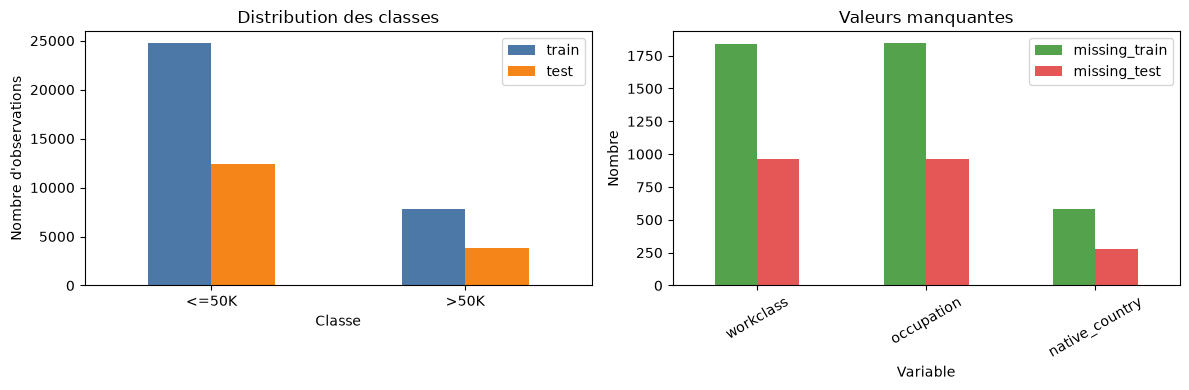

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_summary[["train", "test"]].plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("Distribution des classes")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Nombre d'observations")
axes[0].tick_params(axis="x", rotation=0)

missing_summary[missing_summary["missing_total"] > 0][["missing_train", "missing_test"]].plot(
    kind="bar", ax=axes[1], color=["#54A24B", "#E45756"]
)
axes[1].set_title("Valeurs manquantes")
axes[1].set_xlabel("Variable")
axes[1].set_ylabel("Nombre")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

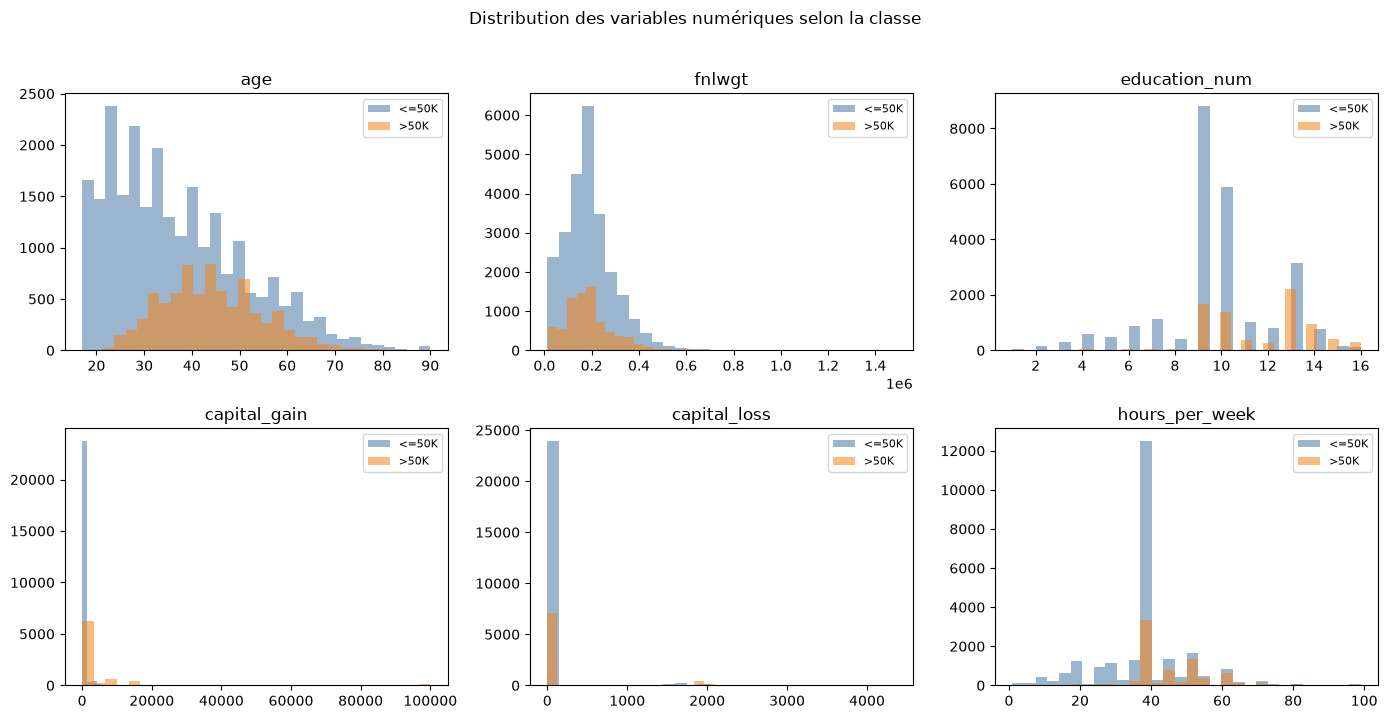

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC_COLUMNS):
    for label, color in [("<=50K", "#4C78A8"), (">50K", "#F58518")]:
        ax.hist(train_df.loc[train_df["income"] == label, col].dropna(), bins=30, alpha=0.55, label=label, color=color)
    ax.set_title(col)
    ax.legend(fontsize=8)
plt.suptitle("Distribution des variables numériques selon la classe", y=1.02)
plt.tight_layout()
plt.show()

## 5. Préparation des données

Les valeurs `?` sont considérées comme manquantes. Les variables numériques sont imputées par la médiane puis normalisées. Les variables catégorielles sont imputées par la modalité la plus fréquente puis encodées par One-Hot Encoding. Le preprocessing est ajusté uniquement sur le train pour éviter la fuite de données.

La séparation utilisée est :

- `adult.data` -> train + validation ;
- `adult.test` -> test final officiel.

In [33]:
train_loader, val_loader, test_loader, input_dim, preprocessor, data_info = prepare_data(
    train_df, test_df, BATCH_SIZE, SEED
)
display(pd.DataFrame([data_info]))
print("Dimension d'entrée après preprocessing :", input_dim)

,train_rows_raw,test_rows_raw,train_rows,val_rows,test_rows,missing_train,missing_test,class_train,class_val,class_test
0,32561,16281,27676,4885,16281,4262,2203,"{0: 21011, 1: 6665}","{0: 3709, 1: 1176}","{0: 12435, 1: 3846}"


Dimension d'entrée après preprocessing : 105


## 6. Implémentation du MLP avec `nn.Sequential`

`nn.Sequential` empile les couches dans un ordre fixe. L'architecture utilisée est :

`Linear(input_dim, 128) -> ReLU -> Linear(128, 64) -> ReLU -> Linear(64, 2)`.

In [34]:
sequential_model = build_sequential_mlp(input_dim, HIDDEN1, HIDDEN2)
print(sequential_model)

Sequential(
  (0): Linear(in_features=105, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=2, bias=True)
)


## 7. Implémentation du MLP avec une classe personnalisée `nn.Module`

Une classe personnalisée est plus flexible : elle définit explicitement les couches dans `__init__()` et le calcul dans `forward()`. Ici, on ajoute du Dropout pour régulariser le modèle.

In [35]:
custom_model = AdultIncomeMLP(input_dim, HIDDEN1, HIDDEN2, dropout=DROPOUT)
print(custom_model)

AdultIncomeMLP(
  (fc1): Linear(in_features=105, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=2, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)


## 8. Inspection des paramètres du modèle

On inspecte les poids et biais avec `named_parameters()` puis les tenseurs sauvegardables avec `state_dict()`.

In [36]:
params_rows = []
for name, param in custom_model.named_parameters():
    params_rows.append({
        "nom": name,
        "shape": tuple(param.shape),
        "numel": param.numel(),
        "requires_grad": param.requires_grad,
    })
params_df = pd.DataFrame(params_rows)
display(params_df)
print("Total paramètres apprenables :", int(params_df["numel"].sum()))

state_df = pd.DataFrame([
    {"clé": key, "shape": tuple(value.shape), "dtype": str(value.dtype)}
    for key, value in custom_model.state_dict().items()
])
display(state_df)

,nom,shape,numel,requires_grad
0,fc1.weight,"(128, 105)",13440,True
1,fc1.bias,"(128,)",128,True
2,fc2.weight,"(64, 128)",8192,True
3,fc2.bias,"(64,)",64,True
4,fc3.weight,"(2, 64)",128,True
5,fc3.bias,"(2,)",2,True


Total paramètres apprenables : 21954


,clé,shape,dtype
0,fc1.weight,"(128, 105)",torch.float32
1,fc1.bias,"(128,)",torch.float32
2,fc2.weight,"(64, 128)",torch.float32
3,fc2.bias,"(64,)",torch.float32
4,fc3.weight,"(2, 64)",torch.float32
5,fc3.bias,"(2,)",torch.float32


## 9. Initialisation des paramètres

Trois stratégies sont testées :

- **gaussienne** : poids tirés de `N(0, 0.01)` ;
- **constante** : poids fixés à `1`, utile pédagogiquement mais défavorable à cause de la symétrie ;
- **Xavier** : initialisation visant à stabiliser la variance des activations.

In [37]:
display(pd.DataFrame([
    {"initialisation": "Gaussienne", "fonction": "init_gaussian", "principe": "poids ~ N(0, 0.01), biais = 0"},
    {"initialisation": "Constante", "fonction": "init_constant", "principe": "poids = 1, biais = 0"},
    {"initialisation": "Xavier", "fonction": "init_xavier", "principe": "xavier_uniform_, biais = 0"},
]))

,initialisation,fonction,principe
0,Gaussienne,init_gaussian,"poids ~ N(0, 0.01), biais = 0"
1,Constante,init_constant,"poids = 1, biais = 0"
2,Xavier,init_xavier,"xavier_uniform_, biais = 0"


## 10. Configuration de l'entraînement

On utilise `CrossEntropyLoss`, l'optimiseur Adam, un learning rate de `1e-3`, des mini-lots de taille `128`, un scheduler `StepLR` et `35` époques par expérience.

In [38]:
display(pd.DataFrame([{
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "scheduler": "StepLR(step_size=15, gamma=0.5)",
    "epochs": EPOCHS,
    "weight_decay": 1e-4,
    "dropout_custom": DROPOUT,
}]))

,loss,optimizer,learning_rate,batch_size,scheduler,epochs,weight_decay,dropout_custom
0,CrossEntropyLoss,Adam,0.001,128,"StepLR(step_size=15, gamma=0.5)",35,0.0001,0.3


## 11. Utilisation du CPU/GPU

Le device est détecté automatiquement. Pendant l'entraînement, chaque mini-lot est déplacé vers le même device que le modèle.

In [39]:
probe_model = AdultIncomeMLP(input_dim).to(device)
probe_x, probe_y = next(iter(train_loader))
probe_x = probe_x.to(device)
probe_y = probe_y.to(device)
probe_logits = probe_model(probe_x)
print("Device modèle :", next(probe_model.parameters()).device)
print("Device données :", probe_x.device)
print("Device sortie :", probe_logits.device)
print("Shape logits :", tuple(probe_logits.shape))

Device modèle : cpu
Device données : cpu
Device sortie : cpu
Shape logits : (128, 2)


## 12. Entraînement des modèles

Quatre expériences sont conservées :

1. `Sequential_Xavier`
2. `Custom_Gaussienne`
3. `Custom_Constante`
4. `Custom_Xavier`

Pour chaque expérience, on conserve les poids obtenant la meilleure accuracy de validation.

In [40]:
def train_model_with_epoch(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    init_fn,
    label: str,
    epochs: int,
    lr: float,
    device: torch.device,
) -> tuple[dict[str, list[float]], dict[str, torch.Tensor], float, int]:
    model.apply(init_fn)
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = -1.0
    best_epoch = 0
    best_state = {}

    print(f"\nEntraînement : {label}")
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(
                f"  Epoch {epoch:03d}/{epochs} | "
                f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
            )
    return history, best_state, best_val_acc, best_epoch


experiments = [
    ("Sequential_Xavier", lambda: build_sequential_mlp(input_dim, HIDDEN1, HIDDEN2), init_xavier),
    ("Custom_Gaussienne", lambda: AdultIncomeMLP(input_dim, HIDDEN1, HIDDEN2, dropout=DROPOUT), init_gaussian),
    ("Custom_Constante", lambda: AdultIncomeMLP(input_dim, HIDDEN1, HIDDEN2, dropout=DROPOUT), init_constant),
    ("Custom_Xavier", lambda: AdultIncomeMLP(input_dim, HIDDEN1, HIDDEN2, dropout=DROPOUT), init_xavier),
]

set_seed(SEED)
results = {}
for name, model_factory, init_fn in experiments:
    model = model_factory()
    history, best_state, best_val_acc, best_epoch = train_model_with_epoch(
        model, train_loader, val_loader, init_fn, name, EPOCHS, LEARNING_RATE, device
    )
    results[name] = {
        "history": history,
        "best_state": best_state,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "model_factory": model_factory,
    }


Entraînement : Sequential_Xavier
  Epoch 001/35 | train_loss=0.3470 train_acc=0.8323 | val_loss=0.3155 val_acc=0.8489
  Epoch 005/35 | train_loss=0.2995 train_acc=0.8595 | val_loss=0.2995 val_acc=0.8647
  Epoch 010/35 | train_loss=0.2847 train_acc=0.8684 | val_loss=0.3020 val_acc=0.8596
  Epoch 015/35 | train_loss=0.2707 train_acc=0.8739 | val_loss=0.3095 val_acc=0.8571
  Epoch 020/35 | train_loss=0.2540 train_acc=0.8829 | val_loss=0.3208 val_acc=0.8551
  Epoch 025/35 | train_loss=0.2445 train_acc=0.8856 | val_loss=0.3374 val_acc=0.8577
  Epoch 030/35 | train_loss=0.2351 train_acc=0.8909 | val_loss=0.3407 val_acc=0.8536
  Epoch 035/35 | train_loss=0.2246 train_acc=0.8968 | val_loss=0.3507 val_acc=0.8499

Entraînement : Custom_Gaussienne
  Epoch 001/35 | train_loss=0.3823 train_acc=0.8209 | val_loss=0.3132 val_acc=0.8618
  Epoch 005/35 | train_loss=0.3120 train_acc=0.8588 | val_loss=0.3032 val_acc=0.8612
  Epoch 010/35 | train_loss=0.3047 train_acc=0.8627 | val_loss=0.3010 val_acc=0.86

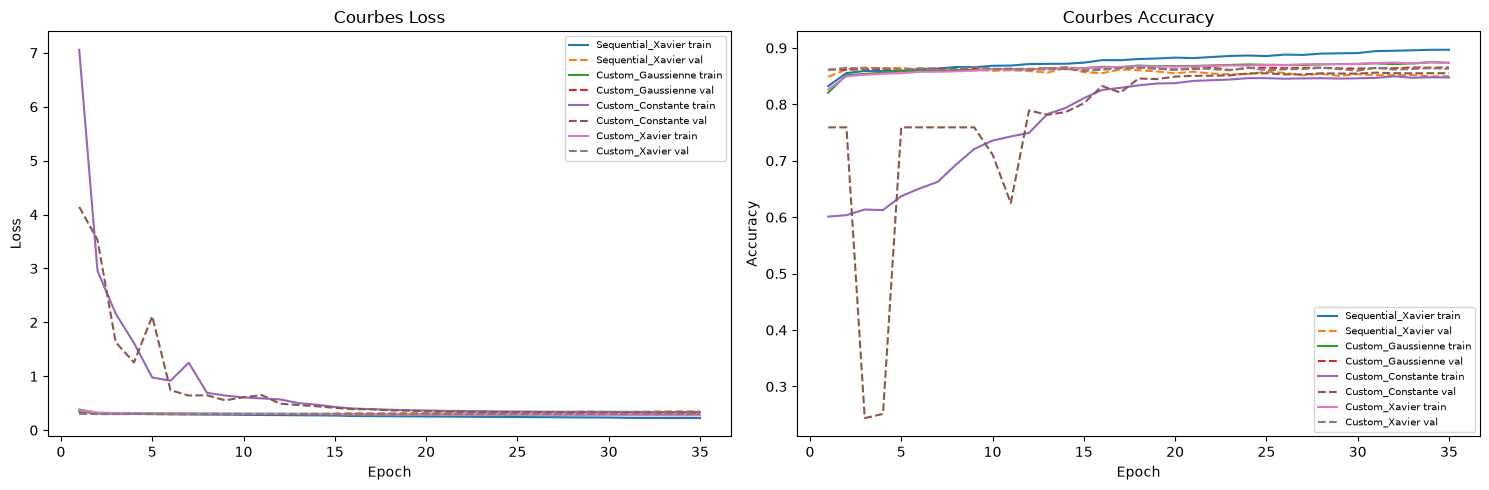

Courbes sauvegardées : ..\outputs\mlp\courbes_mlp_adult_income_final.png


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, result in results.items():
    h = result["history"]
    x = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(x, h["train_loss"], label=f"{name} train")
    axes[0].plot(x, h["val_loss"], linestyle="--", label=f"{name} val")
    axes[1].plot(x, h["train_acc"], label=f"{name} train")
    axes[1].plot(x, h["val_acc"], linestyle="--", label=f"{name} val")

axes[0].set_title("Courbes Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=7)
axes[1].set_title("Courbes Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=7)
plt.tight_layout()
curves_path = OUTPUT_DIR / "courbes_mlp_adult_income_final.png"
plt.savefig(curves_path, dpi=150, bbox_inches="tight")
plt.show()
print("Courbes sauvegardées :", curves_path)

## 13. Comparaison expérimentale

Le tableau comparatif contient l'accuracy validation, l'accuracy test, la précision, le rappel et le F1-score pour chaque expérience. Chaque modèle est évalué sur le test officiel avec les meilleurs poids sélectionnés par validation.

In [42]:
def evaluate_saved_state(model_factory, state_dict, loader):
    model = model_factory().to(device)
    model.load_state_dict(state_dict)
    criterion = nn.CrossEntropyLoss()
    loss, acc, y_pred, y_true = evaluate(model, loader, criterion, device)
    return {
        "test_loss": loss,
        "accuracy_test": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
        "y_pred": y_pred,
        "y_true": y_true,
        "model": model,
    }


rows = []
for name, result in results.items():
    test_result = evaluate_saved_state(result["model_factory"], result["best_state"], test_loader)
    result["test_result"] = test_result
    rows.append({
        "experience": name,
        "best_epoch": result["best_epoch"],
        "accuracy_validation": result["best_val_acc"],
        "accuracy_test": test_result["accuracy_test"],
        "precision": test_result["precision"],
        "recall": test_result["recall"],
        "f1_score": test_result["f1_score"],
        "test_loss": test_result["test_loss"],
    })

comparison_df = pd.DataFrame(rows).sort_values("accuracy_validation", ascending=False)
comparison_path = OUTPUT_DIR / "comparaison_experiences_mlp_adult_income.csv"
comparison_df.to_csv(comparison_path, index=False)
display(comparison_df)
print("Tableau sauvegardé :", comparison_path)

best_name = comparison_df.iloc[0]["experience"]
best_result = results[best_name]
print("Meilleure expérience :", best_name)

,experience,best_epoch,accuracy_validation,accuracy_test,precision,recall,f1_score,test_loss
3,Custom_Xavier,9,0.866325,0.856950,0.734757,0.617265,0.670906,0.309120
1,Custom_Gaussienne,14,0.865711,0.856151,0.744314,0.595684,0.661756,0.310306
0,Sequential_Xavier,3,0.865302,0.855230,0.732729,0.609464,0.665436,0.310784
2,Custom_Constante,31,0.856295,0.852405,0.731176,0.593344,0.655088,0.331679


Tableau sauvegardé : ..\outputs\mlp\comparaison_experiences_mlp_adult_income.csv
Meilleure expérience : Custom_Xavier


## 14. Sauvegarde et rechargement du meilleur modèle

On sauvegarde le `state_dict()` du meilleur modèle, puis on recrée l'architecture et on recharge les poids avec `load_state_dict()`.

In [43]:
best_model = best_result["model_factory"]().to(device)
best_model.load_state_dict(best_result["best_state"])

model_path = OUTPUT_DIR / "best_mlp_adult_income_final.params"
torch.save(best_model.state_dict(), model_path)
print("Modèle sauvegardé :", model_path)

reloaded_model = best_result["model_factory"]().to(device)
reloaded_model.load_state_dict(torch.load(model_path, map_location=device))
reloaded_model.eval()
criterion = nn.CrossEntropyLoss()
reload_loss, reload_acc, y_pred, y_true = evaluate(reloaded_model, test_loader, criterion, device)
print("Rechargement réussi.")
print("Loss test :", round(reload_loss, 4))
print("Accuracy test :", round(reload_acc, 4))
print("Device modèle rechargé :", next(reloaded_model.parameters()).device)

Modèle sauvegardé : ..\outputs\mlp\best_mlp_adult_income_final.params
Rechargement réussi.
Loss test : 0.3091
Accuracy test : 0.8569
Device modèle rechargé : cpu


## 15. Évaluation finale

L'évaluation finale du meilleur modèle est effectuée sur `adult.test`. On affiche accuracy, precision, recall, F1-score, classification report et matrice de confusion.

In [44]:
final_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
}
display(pd.DataFrame([final_metrics]))
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

,accuracy,precision,recall,f1_score
0,0.85695,0.734757,0.617265,0.670906


              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91     12435
        >50K       0.73      0.62      0.67      3846

    accuracy                           0.86     16281
   macro avg       0.81      0.77      0.79     16281
weighted avg       0.85      0.86      0.85     16281



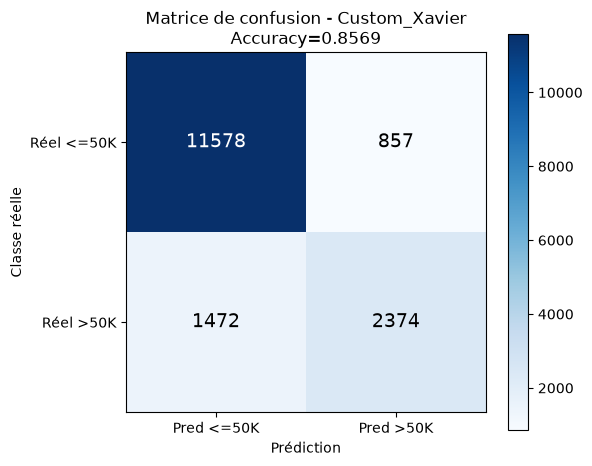

Matrice sauvegardée : ..\outputs\mlp\matrice_confusion_mlp_adult_income_final.png


In [45]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred <=50K", "Pred >50K"])
ax.set_yticklabels(["Réel <=50K", "Réel >50K"])
ax.set_xlabel("Prédiction")
ax.set_ylabel("Classe réelle")
ax.set_title(f"Matrice de confusion - {best_name}\nAccuracy={final_metrics['accuracy']:.4f}")
threshold = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > threshold else "black", fontsize=14)
fig.colorbar(im, ax=ax)
plt.tight_layout()
cm_path = OUTPUT_DIR / "matrice_confusion_mlp_adult_income_final.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print("Matrice sauvegardée :", cm_path)

## 16. Analyse critique des résultats

Le MLP obtient des performances solides sur Adult Income, avec une accuracy généralement proche de 85-86 %. Cependant, le dataset est déséquilibré : la classe `<=50K` est majoritaire. Il faut donc interpréter l'accuracy avec prudence et tenir compte du rappel, de la précision et du F1-score pour la classe `>50K`.

**Forces du MLP :** il apprend des frontières non linéaires, s'intègre naturellement à PyTorch et permet d'étudier les paramètres, gradients, initialisations, sauvegarde et rechargement.

**Faiblesses du MLP :** il dépend fortement du preprocessing, ne modélise pas naturellement les interactions tabulaires comme les méthodes à arbres, et peut être sensible au déséquilibre de classes.

**Impact du preprocessing :** la normalisation stabilise l'optimisation et le One-Hot Encoding rend les catégories utilisables par des couches linéaires.

**Impact des initialisations :** l'initialisation constante est défavorable à cause de la symétrie ; Xavier et la gaussienne conduisent à une optimisation plus stable.

## 17. Réponse complète à la question de synthèse

**Question :** Dans quelle mesure un MLP bien paramétré constitue-t-il une solution pertinente pour la classification tabulaire sur un dataset réel, et quelles sont ses principales limites au regard de la structure statistique des données étudiées ?

Un MLP bien paramétré constitue une solution pertinente pour la classification tabulaire lorsque les données sont transformées en une représentation numérique cohérente. Dans Adult Income, les variables numériques sont normalisées et les variables catégorielles sont encodées par One-Hot Encoding. Cette transformation permet de représenter chaque individu par un vecteur numérique compatible avec des couches `Linear`.

Sur le plan théorique, le MLP combine transformations linéaires et activations non linéaires. Il peut donc apprendre des frontières de décision plus complexes qu'un modèle linéaire simple. Sur le plan méthodologique, le protocole respecte les bonnes pratiques : séparation train/validation/test, preprocessing ajusté uniquement sur le train, comparaison d'architectures et d'initialisations, sauvegarde du meilleur `state_dict()` et test final sur le fichier officiel.

Les résultats expérimentaux montrent que le MLP apprend une relation utile entre les variables socio-économiques et la classe de revenu. Toutefois, ses limites restent nettes. Le dataset est déséquilibré, donc une bonne accuracy globale peut masquer un rappel plus faible sur la classe `>50K`. De plus, le MLP dépend fortement du preprocessing et le One-Hot Encoding peut ignorer certaines relations statistiques entre modalités. Enfin, sur données tabulaires, des modèles comme Random Forest, XGBoost ou LightGBM sont souvent très compétitifs.

Ainsi, le MLP est une solution pédagogique et fonctionnelle pour Adult Income, surtout pour démontrer l'ingénierie PyTorch. Ses principales limites concernent la structure statistique tabulaire, le déséquilibre de classes et la dépendance à l'encodage des variables.

## 18. Conclusion générale

Cette partie a construit un pipeline complet de classification tabulaire avec PyTorch. Le dataset Adult Income a été nettoyé, encodé, normalisé puis utilisé pour entraîner plusieurs MLP. Les expériences ont comparé `nn.Sequential`, une classe personnalisée `nn.Module` et trois stratégies d'initialisation.

Le travail confirme l'importance du preprocessing, de l'initialisation, de la validation et des métriques adaptées. Les perspectives d'amélioration incluent la pondération de la loss, l'early stopping, la recherche d'hyperparamètres et la comparaison avec des modèles tabulaires classiques.